<a href="https://colab.research.google.com/github/jostina/Netflix-Dataset/blob/main/Task_%E2%80%93_Netflix_Machine_Learning_Classification_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1: Import libraries

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

Step 2: Load the clean Netflix dataset

In [2]:
# Load the clean Netflix dataset
df = pd.read_csv("/content/netflix_titles_cleaned.csv")

# Display the first five rows
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,date_added_year,date_added_month,date_added_month_name,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,9,September,90,min
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,9,September,1,Season
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,9,September,1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,9,September,91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,9,September,125,min


In [3]:
# Dataset information
df.info()

# Check dataset shape
print("Dataset shape:", df.shape)

# Check missing values
print(df.isnull().sum())

# Check duplicate records
print("Duplicates:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   show_id                8790 non-null   object
 1   type                   8790 non-null   object
 2   title                  8790 non-null   object
 3   director               8790 non-null   object
 4   country                8790 non-null   object
 5   date_added             8790 non-null   object
 6   release_year           8790 non-null   int64 
 7   rating                 8790 non-null   object
 8   duration               8790 non-null   object
 9   listed_in              8790 non-null   object
 10  date_added_year        8790 non-null   int64 
 11  date_added_month       8790 non-null   int64 
 12  date_added_month_name  8790 non-null   object
 13  duration_value         8790 non-null   int64 
 14  duration_unit          8790 non-null   object
dtypes: int64(4), object(1

Step 3: Explore the target variable

type
Movie      6126
Tv Show    2664
Name: count, dtype: int64


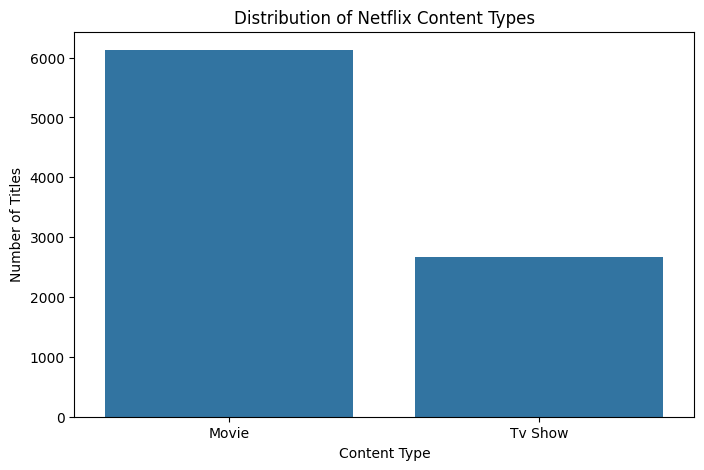

In [4]:
# Count the different content types
print(df["type"].value_counts())

# Visualize content distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="type")

plt.title("Distribution of Netflix Content Types")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.show()

Step 4: Select and prepare features

In [5]:
# Select features
features = [
    "release_year",
    "rating",
    "country",
    "listed_in",
    "duration"
]

# Define independent variables
X = df[features].copy()

# Define target variable
y = df["type"]

# Display selected features
X.head()

,release_year,rating,country,listed_in,duration
0,2020,PG-13,United States,Documentaries,90 min
1,2021,TV-MA,France,"Crime TV Shows, International TV Shows, TV Act...",1 Season
2,2021,TV-MA,United States,"TV Dramas, TV Horror, TV Mysteries",1 Season
3,2021,TV-PG,Brazil,"Children & Family Movies, Comedies",91 min
4,1993,TV-MA,United States,"Dramas, Independent Movies, International Movies",125 min


In [6]:
# Fill missing numerical values
X["release_year"] = X["release_year"].fillna(
    X["release_year"].median()
)

# Fill missing categorical values
categorical_columns = [
    "rating",
    "country",
    "listed_in",
    "duration"
]

for column in categorical_columns:
    X[column] = X[column].fillna("Unknown")

# Check missing values
print(X.isnull().sum())

release_year    0
rating          0
country         0
listed_in       0
duration        0
dtype: int64


Step 5: Split the dataset into training and testing sets
We will use an 80:20 split.
- 80% for training.
- 20% for testing.

In [7]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (7032, 5)
Testing features: (1758, 5)
Training target: (7032,)
Testing target: (1758,)


Step 6: Preprocess the features
Machine learning algorithms require numerical inputs.

We will use:
- StandardScaler to scale the release year.
- OneHotEncoder to convert categorical features into numerical values.

In [8]:
# Define numerical features
numerical_features = ["release_year"]

# Define categorical features
categorical_features = [
    "rating",
    "country",
    "listed_in",
    "duration"
]

# Create numerical preprocessing pipeline
numerical_transformer = StandardScaler()

# Create categorical preprocessing pipeline
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

Step 7: Train classification models
We will train three classification algorithms.

Model 1: Logistic Regression

In [9]:
# Create Logistic Regression pipeline
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

# Train the model
logistic_model.fit(X_train, y_train)

# Make predictions
y_pred_logistic = logistic_model.predict(X_test)

print("Logistic Regression training completed!")

Logistic Regression training completed!


Model 2: Decision Tree Classifier

In [10]:
# Create Decision Tree pipeline
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=10,
            random_state=42
        ))
    ]
)

# Train the model
decision_tree_model.fit(X_train, y_train)

# Make predictions
y_pred_tree = decision_tree_model.predict(X_test)

print("Decision Tree training completed!")

Decision Tree training completed!


Model 3: Random Forest Classifier

In [11]:
# Create Random Forest pipeline
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_depth=15,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train the model
random_forest_model.fit(X_train, y_train)

# Make predictions
y_pred_forest = random_forest_model.predict(X_test)

print("Random Forest training completed!")

Random Forest training completed!


Step 8: Evaluate model performance
We will evaluate each model using:
- Accuracy: Overall percentage of correct predictions.
- Precision: How many predicted class labels were correct.
- Recall: How many actual class labels were correctly identified.
- F1-score: Balance between precision and recall.

In [12]:
# Create a function to evaluate models
def evaluate_model(y_true, y_pred, model_name):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }

In [13]:
# Evaluate all classification models
results = []

results.append(
    evaluate_model(y_test, y_pred_logistic, "Logistic Regression")
)

results.append(
    evaluate_model(y_test, y_pred_tree, "Decision Tree")
)

results.append(
    evaluate_model(y_test, y_pred_forest, "Random Forest")
)

# Convert results into a DataFrame
results_df = pd.DataFrame(results)

# Display model performance
results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
1,Decision Tree,0.998862,0.998864,0.998862,0.998862
0,Logistic Regression,0.996587,0.996604,0.996587,0.996582
2,Random Forest,0.977816,0.978500,0.977816,0.977568


Step 9: Compare model accuracy
Visualize the accuracy of the three classification algorithms.

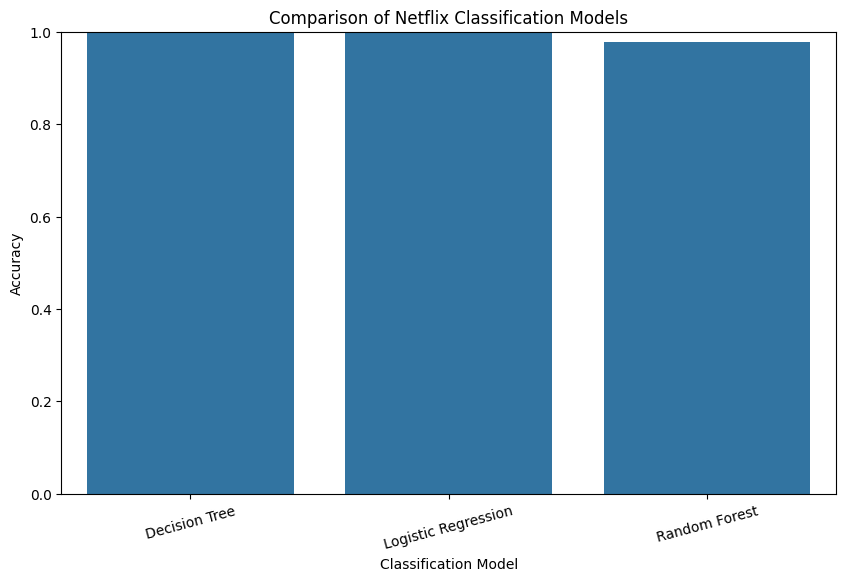

In [14]:
# Plot model accuracy
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Comparison of Netflix Classification Models")
plt.xlabel("Classification Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.show()

In [15]:
# Print model accuracy
for index, row in results_df.iterrows():

    print(
        f"{row['Model']}: "
        f"{row['Accuracy']:.4f}"
    )

Decision Tree: 0.9989
Logistic Regression: 0.9966
Random Forest: 0.9778


Step 10: Generate classification reports
Classification reports provide detailed information about the model's performance for each class.

In [16]:
# Logistic Regression report
print("LOGISTIC REGRESSION")
print(
    classification_report(
        y_test,
        y_pred_logistic
    )
)

# Decision Tree report
print("DECISION TREE")
print(
    classification_report(
        y_test,
        y_pred_tree
    )
)

# Random Forest report
print("RANDOM FOREST")
print(
    classification_report(
        y_test,
        y_pred_forest
    )
)

LOGISTIC REGRESSION
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1225
     Tv Show       1.00      0.99      0.99       533

    accuracy                           1.00      1758
   macro avg       1.00      0.99      1.00      1758
weighted avg       1.00      1.00      1.00      1758

DECISION TREE
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1225
     Tv Show       1.00      1.00      1.00       533

    accuracy                           1.00      1758
   macro avg       1.00      1.00      1.00      1758
weighted avg       1.00      1.00      1.00      1758

RANDOM FOREST
              precision    recall  f1-score   support

       Movie       0.97      1.00      0.98      1225
     Tv Show       1.00      0.93      0.96       533

    accuracy                           0.98      1758
   macro avg       0.98      0.96      0.97      1758
weighted avg       0.98   

Step 11: Visualize the confusion matrix
A confusion matrix helps us understand how many Movies and TV Shows were correctly and incorrectly classified.

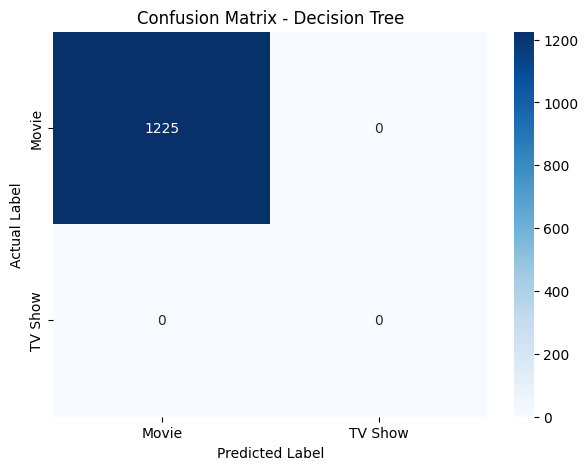

In [17]:
# Select the best model based on accuracy
best_model_name = results_df.iloc[0]["Model"]

predictions = {
    "Logistic Regression": y_pred_logistic,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_forest
}

best_predictions = predictions[best_model_name]

# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=["Movie", "TV Show"]
)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Movie", "TV Show"],
    yticklabels=["Movie", "TV Show"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

Step 12: Identify the best-performing model

In [18]:
# Find the best-performing model
best_model = results_df.iloc[0]

print("Best Performing Model")
print("---------------------")

print("Model:", best_model["Model"])

print(
    "Accuracy:",
    round(best_model["Accuracy"] * 100, 2),
    "%"
)

print(
    "Precision:",
    round(best_model["Precision"], 4)
)

print(
    "Recall:",
    round(best_model["Recall"], 4)
)

print(
    "F1 Score:",
    round(best_model["F1 Score"], 4)
)

Best Performing Model
---------------------
Model: Decision Tree
Accuracy: 99.89 %
Precision: 0.9989
Recall: 0.9989
F1 Score: 0.9989


Step 13: Test the best model with new data
We can use the best-performing model to classify a new Netflix title based on its features.

In [19]:
# Select the best trained model
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

best_classifier = models[best_model_name]

# Create sample Netflix content
new_content = pd.DataFrame({
    "release_year": [2023],
    "rating": ["TV-MA"],
    "country": ["United States"],
    "listed_in": ["Dramas, International TV Shows"],
    "duration": ["3 Seasons"]
})

# Predict content type
prediction = best_classifier.predict(new_content)

print("Predicted Netflix Content Type:", prediction[0])

Predicted Netflix Content Type: Tv Show
